Final Accuracy: 0.8207
Final F1 Score: 0.8390

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.87      0.80        75
           1       0.90      0.79      0.84       109

    accuracy                           0.82       184
   macro avg       0.82      0.83      0.82       184
weighted avg       0.83      0.82      0.82       184



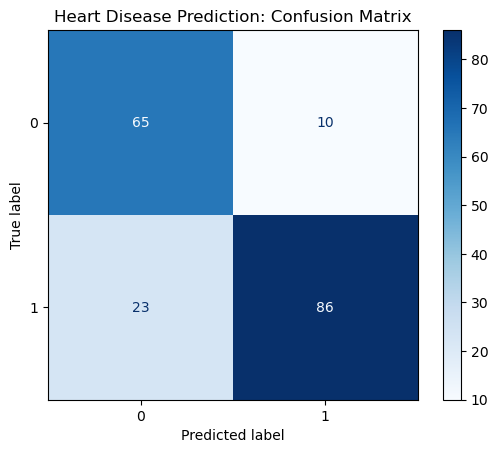

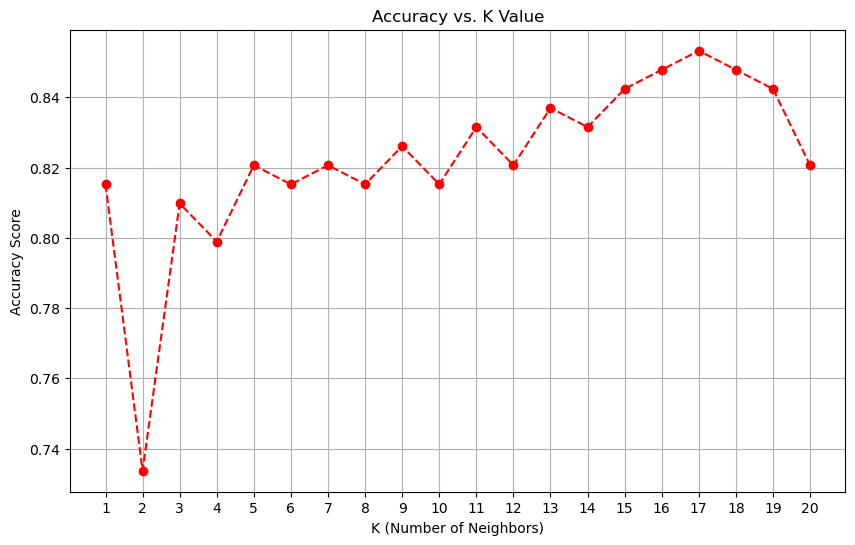

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
# Consolidated metrics imports here
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

# --- STEP 1: LOAD DATA ---
df = pd.read_csv('heart_disease_uci.csv')

# --- STEP 2: PREPROCESSING ---
df = df.drop(columns=['id', 'ca', 'thal', 'slope'])

# Simplify the target: 0 = Healthy, 1 = Heart Disease
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns=['num'])

# Handle Missing Values
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop('target')
imputer_num = SimpleImputer(strategy='median')
df[num_cols] = imputer_num.fit_transform(df[num_cols])

cat_cols = df.select_dtypes(include=['object', 'bool']).columns
imputer_cat = SimpleImputer(strategy='most_frequent')
df[cat_cols] = imputer_cat.fit_transform(df[cat_cols])

# Encode Categorical Variables
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# --- STEP 3: SPLIT DATA ---
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- STEP 4: FEATURE SCALING ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# --- STEP 5: TRAIN THE MODEL ---
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# --- STEP 6: EVALUATION ---
y_pred = knn.predict(X_test)

# NEW: Calculate and print the specific scores
final_acc = accuracy_score(y_test, y_pred)
final_f1 = f1_score(y_test, y_pred)

print(f"Final Accuracy: {final_acc:.4f}")
print(f"Final F1 Score: {final_f1:.4f}") # Added this line

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

# Visualizing the Errors
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title("Heart Disease Prediction: Confusion Matrix")
plt.show()

# --- STEP 7: FINDING THE OPTIMAL K ---
k_values = range(1, 21)
accuracies = []

for k in k_values:
    temp_knn = KNeighborsClassifier(n_neighbors=k)
    temp_knn.fit(X_train, y_train)
    acc = temp_knn.score(X_test, y_test)
    accuracies.append(acc)

plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='red')
plt.title('Accuracy vs. K Value')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Accuracy Score')
plt.xticks(k_values)
plt.grid(True)
plt.show()